In [1]:
!pip install mlxtend

In [2]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# ============================================================
# LOAD DATASET 60 TRANSAKSI
# ============================================================
# Opsi A: dari file CSV
# df_raw = pd.read_csv('transactions_arm_praktikum (1).csv')
# transactions = df_raw['Items'].apply(lambda x: [i.strip() for i in x.split(',')]).tolist()

# Opsi B: list of list langsung (agar bisa dijalankan tanpa file)
transactions = [
    ['Gula','Kopi','Susu'],
    ['Gula','Kopi','Susu'],
    ['Mentega','Roti','Susu','Telur'],
    ['Mie Instan'],
    ['Keju','Roti','Susu','Telur'],
    ['Sabun','Shampo'],
    ['Gula','Kopi','Susu','Teh'],
    ['Sabun','Shampo'],
    ['Gula','Kopi'],
    ['Mie Instan','Telur'],
    ['Gula','Mie Instan','Teh'],
    ['Mentega','Roti','Susu'],
    ['Gula','Kecap','Shampo'],
    ['Sabun','Shampo','Teh'],
    ['Sabun','Shampo'],
    ['Kecap','Mie Instan','Telur'],
    ['Kopi'],
    ['Mentega','Roti','Susu'],
    ['Keju','Mentega','Roti','Susu'],
    ['Sabun'],
    ['Mentega','Roti','Susu','Telur'],
    ['Mentega','Roti','Susu'],
    ['Roti'],
    ['Kecap','Mie Instan','Sabun','Teh'],
    ['Kecap','Mie Instan','Telur'],
    ['Mentega','Roti','Susu'],
    ['Kecap','Mie Instan','Telur'],
    ['Gula','Kecap','Keju','Mentega'],
    ['Keju','Kopi','Mentega','Shampo'],
    ['Sabun','Shampo'],
    ['Mie Instan','Telur'],
    ['Kopi','Mentega','Sabun','Shampo'],
    ['Mie Instan','Sabun','Telur'],
    ['Gula','Kopi'],
    ['Sabun'],
    ['Gula','Kecap','Mie Instan','Telur'],
    ['Mentega','Roti'],
    ['Mentega','Shampo','Telur'],
    ['Mentega','Roti','Susu'],
    ['Kecap','Mie Instan'],
    ['Sabun'],
    ['Kopi'],
    ['Keju','Roti','Sabun','Shampo','Susu'],
    ['Sabun','Shampo'],
    ['Gula','Kecap','Mie Instan','Shampo','Telur'],
    ['Mie Instan','Telur'],
    ['Kopi','Roti'],
    ['Kecap','Mie Instan'],
    ['Mentega','Roti'],
    ['Mie Instan','Sabun','Shampo','Susu'],
    ['Kecap','Roti'],
    ['Keju','Mentega','Roti','Susu','Telur'],
    ['Mie Instan','Telur'],
    ['Gula','Kopi'],
    ['Gula','Kecap','Mie Instan'],
    ['Mentega','Roti','Susu'],
    ['Mie Instan'],
    ['Mentega','Roti','Susu'],
    ['Gula','Kopi','Susu'],
    ['Gula','Kopi','Sabun','Susu'],
]

# ============================================================
# ENCODING ONE-HOT
# ============================================================
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Jumlah transaksi :', len(transactions))
print('Ukuran matriks   :', df.shape)

# ============================================================
# BASELINE (Bagian 4.3–4.4) — min_support=0.15, min_confidence=0.5
# ============================================================
freq_base = apriori(df, min_support=0.15, use_colnames=True)
rules_base = association_rules(freq_base, metric='confidence', min_threshold=0.5)
rules_base = rules_base.sort_values('lift', ascending=False).reset_index(drop=True)

print('\n--- BASELINE ---')
print('Jumlah frequent itemset :', len(freq_base))
print('Jumlah aturan           :', len(rules_base))

Jumlah transaksi : 60
Ukuran matriks   : (60, 12)

--- BASELINE ---
Jumlah frequent itemset : 17
Jumlah aturan           : 18


=== min_support = 0.10 ===
Jumlah frequent itemset : 19
Jumlah aturan asosiasi  : 20

Daftar frequent itemset:
 support              itemsets
0.316667                (Susu)
0.300000                (Roti)
0.300000          (Mie Instan)
0.283333             (Mentega)
0.250000               (Telur)
0.250000               (Sabun)
0.233333                (Gula)
0.216667                (Kopi)
0.216667              (Shampo)
0.216667       (Mentega, Roti)
0.216667          (Roti, Susu)
0.200000               (Kecap)
0.183333       (Mentega, Susu)
0.183333 (Roti, Mentega, Susu)
0.166667   (Telur, Mie Instan)
0.150000   (Kecap, Mie Instan)
0.150000       (Shampo, Sabun)
0.133333          (Kopi, Gula)
0.100000                (Keju)

Daftar aturan (urut Lift desc):
    antecedents     consequents  support  confidence  lift
(Mentega, Susu)          (Roti)    0.183       1.000 3.333
         (Roti) (Mentega, Susu)    0.183       0.611 3.333
   (Roti, Susu)       (Mentega)    0.183       0.846 2.986


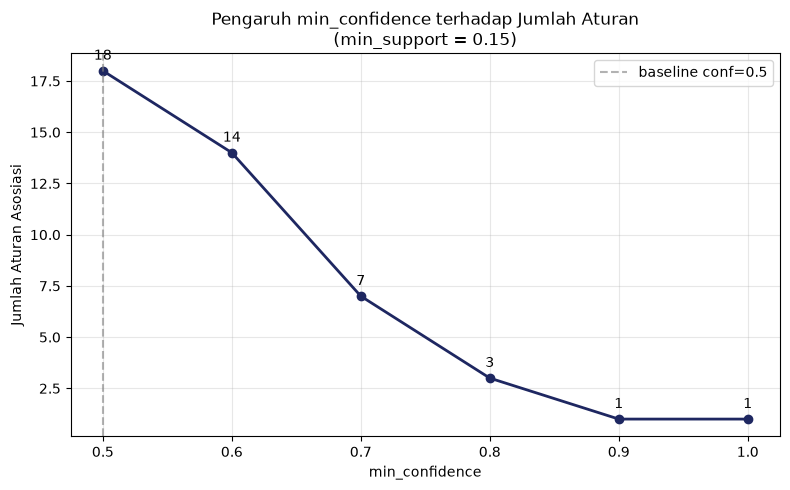

In [3]:
# ============================================================
# TUGAS 1.1 — min_support = 0.10
# ============================================================
freq_010 = apriori(df, min_support=0.10, use_colnames=True)
freq_010 = freq_010.sort_values('support', ascending=False).reset_index(drop=True)
rules_010 = association_rules(freq_010, metric='confidence', min_threshold=0.5)
rules_010 = rules_010.sort_values('lift', ascending=False).reset_index(drop=True)

print('=== min_support = 0.10 ===')
print('Jumlah frequent itemset :', len(freq_010))
print('Jumlah aturan asosiasi  :', len(rules_010))
print('\nDaftar frequent itemset:')
print(freq_010.to_string(index=False))

print('\nDaftar aturan (urut Lift desc):')
cols = ['antecedents','consequents','support','confidence','lift']
print(rules_010[cols].round(3).to_string(index=False))

# Perbandingan dengan baseline
print('\n=== PERBANDINGAN ===')
print(f'Baseline (0.15): {len(freq_base)} itemset, {len(rules_base)} aturan')
print(f'Baru     (0.10): {len(freq_010)} itemset, {len(rules_010)} aturan')
print(f'Selisih itemset : +{len(freq_010)-len(freq_base)}')
print(f'Selisih aturan  : +{len(rules_010)-len(rules_base)}')

# ============================================================
# TUGAS 1.2 — min_confidence = 0.7 (min_support tetap 0.15)
# ============================================================
rules_07 = association_rules(freq_base, metric='confidence', min_threshold=0.7)
rules_07 = rules_07.sort_values('lift', ascending=False).reset_index(drop=True)

print('=== min_confidence = 0.7 ===')
print('Jumlah aturan yang lolos :', len(rules_07), 'dari', len(rules_base), 'aturan awal')

# Aturan yang gugur (ada di baseline tapi tidak di 0.7)
def rule_key(r):
    return (frozenset(r['antecedents']), frozenset(r['consequents']))

set_base = set(rule_key(r) for _, r in rules_base.iterrows())
set_07   = set(rule_key(r) for _, r in rules_07.iterrows())
gugur    = set_base - set_07

print(f'\nJumlah aturan gugur: {len(gugur)}')
print('Aturan yang gugur:')
for ant, cons in gugur:
    row = rules_base[(rules_base['antecedents'].apply(frozenset)==ant) &
                     (rules_base['consequents'].apply(frozenset)==cons)].iloc[0]
    print(f"  {set(ant)} -> {set(cons)} | conf={row['confidence']:.3f} | lift={row['lift']:.3f}")

print('\nAturan yang LOLOS (conf >= 0.7):')
cols = ['antecedents','consequents','support','confidence','lift']
print(rules_07[cols].round(3).to_string(index=False))

# ============================================================
# TUGAS 1.3 — Sweep min_confidence [0.5 ... 1.0]
# ============================================================
conf_sweep = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
hasil = []
for c in conf_sweep:
    r = association_rules(freq_base, metric='confidence', min_threshold=c)
    hasil.append((c, len(r)))

print('=== Sweep min_confidence (min_support=0.15) ===')
for c, n in hasil:
    print(f'min_confidence={c:.1f} -> {n:2d} aturan')

# Grafik
cs = [h[0] for h in hasil]
ns = [h[1] for h in hasil]
plt.figure(figsize=(8,5))
plt.plot(cs, ns, marker='o', color='#1E2761', linewidth=2)
for x, y in zip(cs, ns):
    plt.annotate(str(y), (x, y), textcoords='offset points', xytext=(0,8), ha='center')
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.6, label='baseline conf=0.5')
plt.xlabel('min_confidence')
plt.ylabel('Jumlah Aturan Asosiasi')
plt.title('Pengaruh min_confidence terhadap Jumlah Aturan\n(min_support = 0.15)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# ============================================================
# TUGAS 2 — Hitung Leverage & Conviction untuk 2 aturan terpilih
# ============================================================
N = len(transactions)

def support_itemset(items):
    """Support itemset (frozenset) dari data transaksi."""
    items = set(items)
    return sum(1 for t in transactions if items.issubset(set(t))) / N

def analisis_aturan(antecedent, consequent):
    X, Y = set(antecedent), set(consequent)
    sX = support_itemset(X)
    sY = support_itemset(Y)
    sXY = support_itemset(X | Y)
    conf = sXY / sX
    lift = conf / sY
    leverage = sXY - sX * sY
    conviction = (1 - sY) / (1 - conf) if conf < 1 else float('inf')
    print(f'Aturan: {sorted(X)} -> {sorted(Y)}')
    print(f'  Support(X)       = {sX:.3f}  ({int(sX*N)}/{N})')
    print(f'  Support(Y)       = {sY:.3f}  ({int(sY*N)}/{N})')
    print(f'  Support(X∪Y)     = {sXY:.3f}  ({int(sXY*N)}/{N})')
    print(f'  Confidence       = {conf:.3f}')
    print(f'  Lift             = {lift:.3f}')
    print(f'  Leverage         = {leverage:.4f}')
    print(f'  Conviction       = {conviction:.3f}' if conviction != float('inf') else f'  Conviction       = inf (conf=1)')
    print()
    return dict(sX=sX, sY=sY, sXY=sXY, conf=conf, lift=lift,
                leverage=leverage, conviction=conviction)

print('='*60)
r1 = analisis_aturan(['Mie Instan'], ['Telur'])
print('='*60)
r2 = analisis_aturan(['Roti'], ['Susu'])

# Tabel perbandingan ringkas
import pandas as pd
tabel = pd.DataFrame([
    {'Aturan':'Mie Instan -> Telur', **r1},
    {'Aturan':'Roti -> Susu', **r2},
])[['Aturan','conf','lift','leverage','conviction']]
print(tabel.round(3).to_string(index=False))

Aturan: ['Mie Instan'] -> ['Telur']
  Support(X)       = 0.300  (18/60)
  Support(Y)       = 0.250  (15/60)
  Support(X∪Y)     = 0.167  (10/60)
  Confidence       = 0.556
  Lift             = 2.222
  Leverage         = 0.0917
  Conviction       = 1.688

Aturan: ['Roti'] -> ['Susu']
  Support(X)       = 0.300  (18/60)
  Support(Y)       = 0.317  (19/60)
  Support(X∪Y)     = 0.217  (13/60)
  Confidence       = 0.722
  Lift             = 2.281
  Leverage         = 0.1217
  Conviction       = 2.460

             Aturan  conf  lift  leverage  conviction
Mie Instan -> Telur 0.556 2.222     0.092       1.688
       Roti -> Susu 0.722 2.281     0.122       2.460


--- min_support = 0.05 ---
Apriori   : 42 itemset | rata-rata    3.360 ms (min 2.706)
FP-Growth : 42 itemset | rata-rata    3.655 ms (min 2.063)
Itemset identik? True
Rasio kecepatan FP/Apriori = 0.92x lebih cepat

=== Pembanding: min_support = 0.15 ===
--- min_support = 0.15 ---
Apriori   : 17 itemset | rata-rata    3.878 ms (min 3.158)
FP-Growth : 17 itemset | rata-rata    3.643 ms (min 2.348)
Itemset identik? True
Rasio kecepatan FP/Apriori = 1.06x lebih cepat

=== RINGKASAN ===
ms=0.05 -> Apriori 3.360 ms vs FP-Growth 3.655 ms | rasio 0.92x
ms=0.15 -> Apriori 3.878 ms vs FP-Growth 3.643 ms | rasio 1.06x


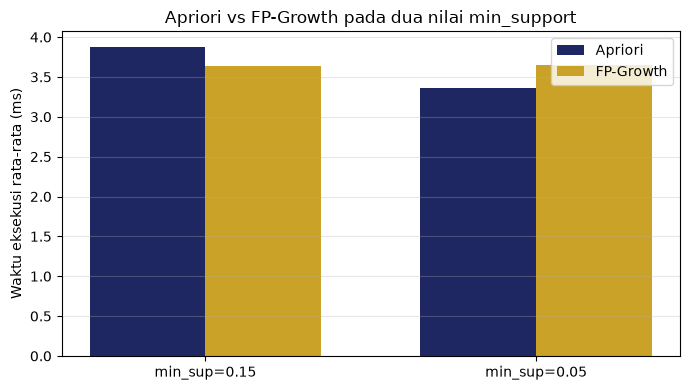

In [5]:
# ============================================================
# TUGAS 3 — Apriori vs FP-Growth pada min_support = 0.05
# ============================================================
def bandingkan(min_sup, n_repeat=5):
    # Apriori
    t_ap = []
    for _ in range(n_repeat):
        t0 = time.perf_counter()
        fi_ap = apriori(df, min_support=min_sup, use_colnames=True)
        t_ap.append((time.perf_counter() - t0) * 1000)  # ms
    # FP-Growth
    t_fp = []
    for _ in range(n_repeat):
        t0 = time.perf_counter()
        fi_fp = fpgrowth(df, min_support=min_sup, use_colnames=True)
        t_fp.append((time.perf_counter() - t0) * 1000)

    set_ap = set(frozenset(s) for s in fi_ap['itemsets'])
    set_fp = set(frozenset(s) for s in fi_fp['itemsets'])
    identik = (set_ap == set_fp)

    print(f'--- min_support = {min_sup} ---')
    print(f'Apriori   : {len(fi_ap):2d} itemset | rata-rata {np.mean(t_ap):8.3f} ms (min {min(t_ap):.3f})')
    print(f'FP-Growth : {len(fi_fp):2d} itemset | rata-rata {np.mean(t_fp):8.3f} ms (min {min(t_fp):.3f})')
    print(f'Itemset identik? {identik}')
    print(f'Rasio kecepatan FP/Apriori = {np.mean(t_ap)/np.mean(t_fp):.2f}x lebih cepat')
    print()
    return fi_ap, fi_fp, np.mean(t_ap), np.mean(t_fp)

fi_ap_005, fi_fp_005, t_ap_005, t_fp_005 = bandingkan(0.05)

# Bandingkan juga dengan baseline 0.15 untuk konteks
print('=== Pembanding: min_support = 0.15 ===')
_, _, t_ap_015, t_fp_015 = bandingkan(0.15)

print('=== RINGKASAN ===')
print(f'ms=0.05 -> Apriori {t_ap_005:.3f} ms vs FP-Growth {t_fp_005:.3f} ms | rasio {t_ap_005/t_fp_005:.2f}x')
print(f'ms=0.15 -> Apriori {t_ap_015:.3f} ms vs FP-Growth {t_fp_015:.3f} ms | rasio {t_ap_015/t_fp_015:.2f}x')

# (Opsional) Grafik perbandingan waktu
labels = ['min_sup=0.15', 'min_sup=0.05']
ap_t = [t_ap_015, t_ap_005]
fp_t = [t_fp_015, t_fp_005]
x = np.arange(len(labels)); w = 0.35

plt.figure(figsize=(7,4))
plt.bar(x-w/2, ap_t, w, label='Apriori', color='#1E2761')
plt.bar(x+w/2, fp_t, w, label='FP-Growth', color='#C9A227')
plt.xticks(x, labels)
plt.ylabel('Waktu eksekusi rata-rata (ms)')
plt.title('Apriori vs FP-Growth pada dua nilai min_support')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [2]:
# ============================================================
# TUGAS 4 — STUDI KASUS MANDIRI
# Petshop & Klinik Hewan "Sehat Pets"
# 50 transaksi, 12 item:
# Makanan Kucing, Pasir Kucing, Snack Kucing, Vitamin Kucing,
# Makanan Anjing, Snack Anjing, Vitamin Anjing, Sampo Hewan,
# Obat Cacing, Kalung Anti Kutu, Mainan, Susu Hewan
# ============================================================
transaksi_petshop = [
    ['Makanan Kucing','Pasir Kucing','Snack Kucing'],                    # T1
    ['Makanan Kucing','Pasir Kucing','Vitamin Kucing'],                  # T2
    ['Makanan Anjing','Snack Anjing','Vitamin Anjing'],                  # T3
    ['Sampo Hewan','Obat Cacing','Kalung Anti Kutu'],                    # T4
    ['Makanan Kucing','Pasir Kucing'],                                   # T5
    ['Makanan Anjing','Snack Anjing'],                                   # T6
    ['Makanan Kucing','Snack Kucing','Susu Hewan'],                      # T7
    ['Sampo Hewan','Kalung Anti Kutu'],                                  # T8
    ['Makanan Kucing','Pasir Kucing','Snack Kucing','Vitamin Kucing'],   # T9
    ['Makanan Anjing','Vitamin Anjing'],                                 # T10
    ['Sampo Hewan','Obat Cacing'],                                       # T11
    ['Makanan Kucing','Pasir Kucing','Mainan'],                          # T12
    ['Makanan Anjing','Snack Anjing','Vitamin Anjing'],                  # T13
    ['Makanan Kucing','Snack Kucing'],                                   # T14
    ['Sampo Hewan','Obat Cacing','Kalung Anti Kutu'],                    # T15
    ['Makanan Kucing','Pasir Kucing','Vitamin Kucing'],                  # T16
    ['Makanan Anjing','Snack Anjing'],                                   # T17
    ['Makanan Kucing','Susu Hewan'],                                     # T18
    ['Sampo Hewan','Kalung Anti Kutu'],                                  # T19
    ['Makanan Anjing','Vitamin Anjing','Snack Anjing'],                  # T20
    ['Makanan Kucing','Pasir Kucing','Snack Kucing'],                    # T21
    ['Obat Cacing','Sampo Hewan'],                                       # T22
    ['Makanan Anjing','Snack Anjing'],                                   # T23
    ['Makanan Kucing','Pasir Kucing','Vitamin Kucing','Mainan'],         # T24
    ['Sampo Hewan','Obat Cacing','Kalung Anti Kutu'],                    # T25
    ['Makanan Anjing','Vitamin Anjing'],                                 # T26
    ['Makanan Kucing','Snack Kucing','Pasir Kucing'],                    # T27
    ['Makanan Anjing','Snack Anjing','Vitamin Anjing'],                  # T28
    ['Sampo Hewan','Kalung Anti Kutu'],                                  # T29
    ['Makanan Kucing','Pasir Kucing'],                                   # T30
    ['Makanan Anjing','Snack Anjing'],                                   # T31
    ['Obat Cacing','Kalung Anti Kutu','Sampo Hewan'],                    # T32
    ['Makanan Kucing','Vitamin Kucing','Snack Kucing'],                  # T33
    ['Makanan Anjing','Vitamin Anjing','Snack Anjing'],                  # T34
    ['Makanan Kucing','Pasir Kucing','Susu Hewan'],                      # T35
    ['Sampo Hewan','Obat Cacing'],                                       # T36
    ['Makanan Anjing','Snack Anjing','Vitamin Anjing'],                  # T37
    ['Makanan Kucing','Snack Kucing'],                                   # T38
    ['Sampo Hewan','Kalung Anti Kutu'],                                  # T39
    ['Makanan Anjing','Snack Anjing'],                                   # T40
    ['Makanan Kucing','Pasir Kucing','Vitamin Kucing'],                  # T41
    ['Sampo Hewan','Obat Cacing','Kalung Anti Kutu'],                    # T42
    ['Makanan Anjing','Vitamin Anjing'],                                 # T43
    ['Makanan Kucing','Pasir Kucing','Snack Kucing','Mainan'],           # T44
    ['Makanan Anjing','Snack Anjing','Vitamin Anjing'],                  # T45
    ['Makanan Kucing','Snack Kucing','Vitamin Kucing'],                  # T46
    ['Sampo Hewan','Obat Cacing'],                                       # T47
    ['Makanan Anjing','Snack Anjing'],                                   # T48
    ['Makanan Kucing','Pasir Kucing','Susu Hewan'],                      # T49
    ['Obat Cacing','Kalung Anti Kutu'],                                  # T50
]

print('Jumlah transaksi :', len(transaksi_petshop))
print('Jumlah item unik :', len(set(i for t in transaksi_petshop for i in t)))
print('Item unik        :', sorted(set(i for t in transaksi_petshop for i in t)))

Jumlah transaksi : 50
Jumlah item unik : 12
Item unik        : ['Kalung Anti Kutu', 'Mainan', 'Makanan Anjing', 'Makanan Kucing', 'Obat Cacing', 'Pasir Kucing', 'Sampo Hewan', 'Snack Anjing', 'Snack Kucing', 'Susu Hewan', 'Vitamin Anjing', 'Vitamin Kucing']


Ukuran matriks one-hot : (50, 12)

Frekuensi kemunculan item:
  Makanan Kucing    : 20 (support = 0.400)
  Makanan Anjing    : 16 (support = 0.320)
  Pasir Kucing      : 14 (support = 0.280)
  Snack Anjing      : 13 (support = 0.260)
  Sampo Hewan       : 13 (support = 0.260)
  Snack Kucing      : 10 (support = 0.200)
  Vitamin Anjing    : 10 (support = 0.200)
  Obat Cacing       : 10 (support = 0.200)
  Kalung Anti Kutu  : 10 (support = 0.200)
  Vitamin Kucing    :  7 (support = 0.140)
  Susu Hewan        :  4 (support = 0.080)
  Mainan            :  3 (support = 0.060)


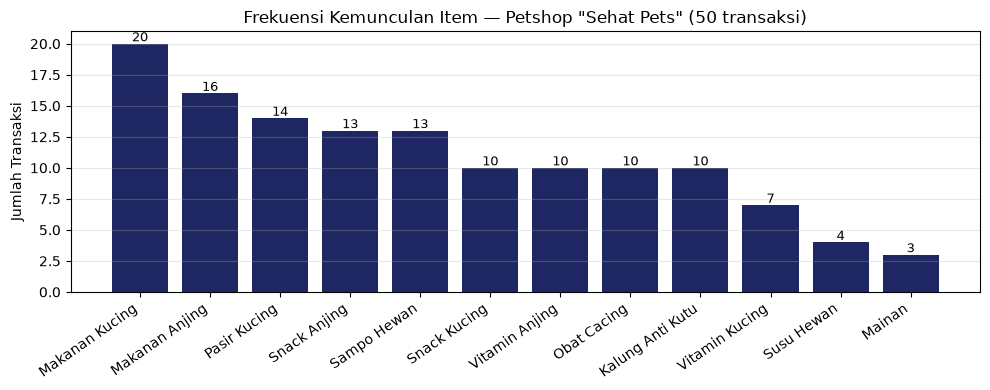


Frequent itemset (min_support=0.1): 25
 support                                       itemsets
    0.40                               (Makanan Kucing)
    0.32                               (Makanan Anjing)
    0.28                                 (Pasir Kucing)
    0.28                 (Makanan Kucing, Pasir Kucing)
    0.26                 (Snack Anjing, Makanan Anjing)
    0.26                                  (Sampo Hewan)
    0.26                                 (Snack Anjing)
    0.20                 (Makanan Kucing, Snack Kucing)
    0.20               (Makanan Anjing, Vitamin Anjing)
    0.20                             (Kalung Anti Kutu)
    0.20                               (Vitamin Anjing)
    0.20                                 (Snack Kucing)
    0.20                                  (Obat Cacing)
    0.18                (Kalung Anti Kutu, Sampo Hewan)
    0.18                     (Sampo Hewan, Obat Cacing)
    0.14                               (Vitamin Kucing)
    0.14

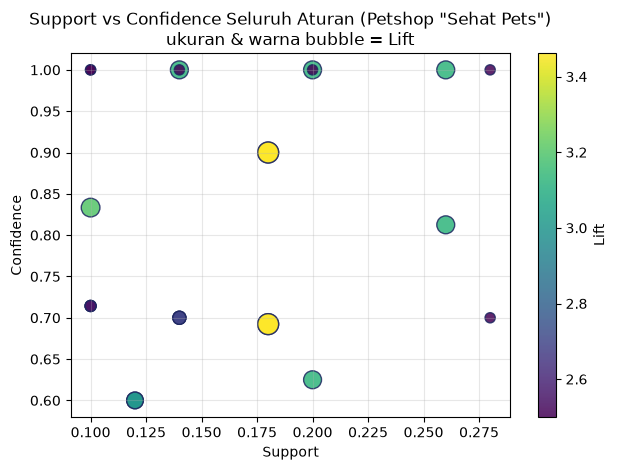

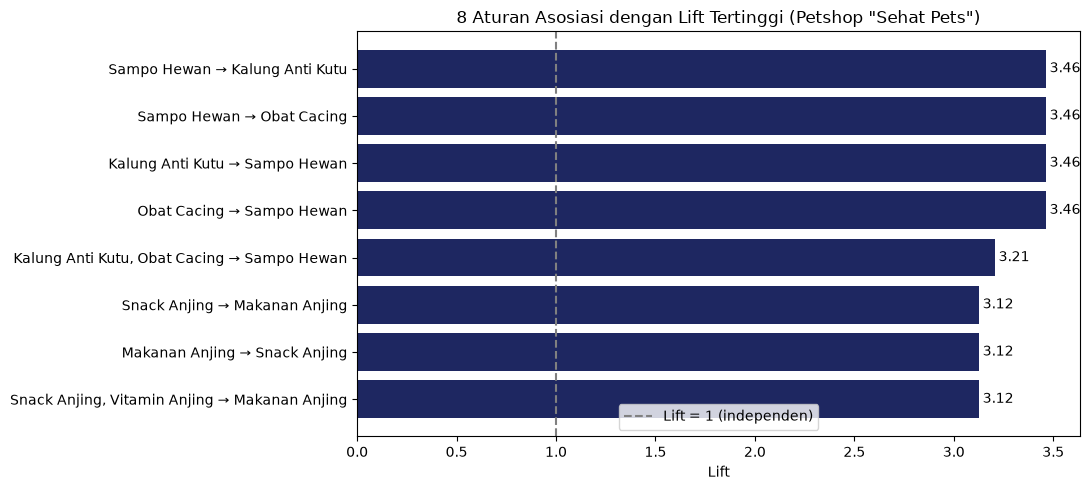

Sweep min_support (min_confidence=0.6):
  min_support=0.05 → 33 itemset, 31 aturan
  min_support=0.10 → 25 itemset, 24 aturan
  min_support=0.15 → 15 itemset, 11 aturan
  min_support=0.20 → 13 itemset,  7 aturan
  min_support=0.25 →  7 itemset,  4 aturan
  min_support=0.30 →  2 itemset,  0 aturan

Sweep min_confidence (min_support=0.10):
  min_confidence=0.5 → 35 aturan
  min_confidence=0.6 → 24 aturan
  min_confidence=0.7 → 19 aturan
  min_confidence=0.8 → 12 aturan
  min_confidence=0.9 →  8 aturan
  min_confidence=1.0 →  8 aturan
5 aturan Lift tertinggi (Petshop "Sehat Pets"):
                    antecedents        consequents  support  confidence  lift
                  (Sampo Hewan) (Kalung Anti Kutu)     0.18       0.692 3.462
                  (Sampo Hewan)      (Obat Cacing)     0.18       0.692 3.462
             (Kalung Anti Kutu)      (Sampo Hewan)     0.18       0.900 3.462
                  (Obat Cacing)      (Sampo Hewan)     0.18       0.900 3.462
(Kalung Anti Kutu, Obat 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# ============================================================
# (a) ENCODING ONE-HOT
# ============================================================
te = TransactionEncoder()
te_ary = te.fit(transaksi_petshop).transform(transaksi_petshop)
df_pet = pd.DataFrame(te_ary, columns=te.columns_)
print('Ukuran matriks one-hot :', df_pet.shape)

# ============================================================
# (b) FREKUENSI ITEM
# ============================================================
cnt = Counter()
for t in transaksi_petshop:
    cnt.update(t)
print('\nFrekuensi kemunculan item:')
for item, freq in cnt.most_common():
    print(f'  {item:18s}: {freq:2d} (support = {freq/len(transaksi_petshop):.3f})')

# Grafik frekuensi
items, freqs = zip(*cnt.most_common())
plt.figure(figsize=(10,4))
bars = plt.bar(items, freqs, color='#1E2761')
for b, f in zip(bars, freqs):
    plt.text(b.get_x()+b.get_width()/2, f+0.2, str(f), ha='center', fontsize=9)
plt.title('Frekuensi Kemunculan Item — Petshop "Sehat Pets" (50 transaksi)')
plt.ylabel('Jumlah Transaksi'); plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# (c) APRIORI + ASSOCIATION RULES
# ============================================================
MIN_SUP_PET = 0.10    # minimal 5 dari 50 transaksi
MIN_CONF_PET = 0.60

freq_pet = apriori(df_pet, min_support=MIN_SUP_PET, use_colnames=True)
freq_pet = freq_pet.sort_values('support', ascending=False).reset_index(drop=True)
rules_pet = association_rules(freq_pet, metric='confidence', min_threshold=MIN_CONF_PET)
rules_pet = rules_pet.sort_values('lift', ascending=False).reset_index(drop=True)

print(f'\nFrequent itemset (min_support={MIN_SUP_PET}): {len(freq_pet)}')
print(freq_pet.round(3).to_string(index=False))

print(f'\nAturan asosiasi (min_confidence={MIN_CONF_PET}): {len(rules_pet)}')
cols = ['antecedents','consequents','support','confidence','lift']
print(rules_pet[cols].round(3).to_string(index=False))

# ============================================================
# (d) SCATTER SUPPORT vs CONFIDENCE (warna = Lift)
# ============================================================
if len(rules_pet) > 0:
    sizes = (rules_pet['lift'] - rules_pet['lift'].min() + 0.3) * 180
    sc = plt.scatter(rules_pet['support'], rules_pet['confidence'],
                     s=sizes, c=rules_pet['lift'], cmap='viridis',
                     alpha=0.85, edgecolor='#1E2761')
    plt.colorbar(sc, label='Lift')
    plt.xlabel('Support'); plt.ylabel('Confidence')
    plt.title('Support vs Confidence Seluruh Aturan (Petshop "Sehat Pets")\nukuran & warna bubble = Lift')
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ============================================================
# (e) BAR CHART TOP-8 ATURAN DENGAN LIFT TERTINGGI
# ============================================================
if len(rules_pet) > 0:
    top8 = rules_pet.head(8).copy()
    top8['label'] = top8['antecedents'].apply(lambda x: ', '.join(sorted(x))) + \
                    ' → ' + top8['consequents'].apply(lambda x: ', '.join(sorted(x)))
    plt.figure(figsize=(11,5))
    plt.barh(top8['label'][::-1], top8['lift'][::-1], color='#1E2761')
    for i, v in enumerate(top8['lift'][::-1]):
        plt.text(v, i, f' {v:.2f}', va='center')
    plt.axvline(1.0, color='gray', linestyle='--', label='Lift = 1 (independen)')
    plt.xlabel('Lift'); plt.title('8 Aturan Asosiasi dengan Lift Tertinggi (Petshop "Sehat Pets")')
    plt.legend(); plt.tight_layout(); plt.show()

    # Sweep untuk mendukung pemilihan
print('Sweep min_support (min_confidence=0.6):')
for s in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    f = apriori(df_pet, min_support=s, use_colnames=True)
    r = association_rules(f, metric='confidence', min_threshold=0.6)
    print(f'  min_support={s:.2f} → {len(f):2d} itemset, {len(r):2d} aturan')

print('\nSweep min_confidence (min_support=0.10):')
for c in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    r = association_rules(freq_pet, metric='confidence', min_threshold=c)
    print(f'  min_confidence={c:.1f} → {len(r):2d} aturan')


    # Tampilkan 5 aturan teratas sebagai dasar rekomendasi
cols = ['antecedents','consequents','support','confidence','lift']
print('5 aturan Lift tertinggi (Petshop "Sehat Pets"):')
print(rules_pet[cols].head(5).round(3).to_string(index=False))